# Болгарский токенизатор: BPE и Unigram

Сравниваем восемь обученных с нуля токенизаторов: два алгоритма × словари **8 192 / 16 384 / 32 768 / 65 536**. Цель — выбрать подходящий компромисс между сжатием текста и стоимостью словаря для LLM около 300M параметров.

Это сравнение токенизации, а не качества обученных LLM. Миллион документов целиком не токенизируется, test не используется. Ноутбук читает сохранённые результаты и не запускает обучение при повторном выполнении.

Код вынесен в пакет `src`; установите его через `bash scripts/setup.sh l40` (или профиль `5080`). Сохранённые результаты относятся к прежнему запуску. Пути берутся из `src.paths` и учитывают `MONOLM_ARTIFACTS`. Команды воспроизведения — в `task1/README.md`.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, Image, Markdown

from src.paths import TASK as ROOT, ARTIFACTS
D = ARTIFACTS / "tokenizers"
def read(name):
    return json.loads((D / name).read_text())
def figure(name):
    display(Image(filename=str(D / "figures" / name)))

manifest = read("manifest.json")
selection = read("selection.json")
comparison = pd.read_parquet(D / "comparison.parquet")
paired = pd.DataFrame(read("paired_comparisons.json"))
estimates = pd.DataFrame(read("corpus_estimates.json"))
verification = read("export_verification.json")
assert verification["passed"]
assert not manifest["test_accessed"] and not manifest["full_corpus_tokenized"]

## Дизайн и воспроизводимость

Из финального Top 1M равномерно выбраны 50 000 документов для обучения и отдельные 5 000 для сравнения (**Top-dev**), seed 42. Обе выборки не пересекаются по ID и нормализованному хешу текста. Ещё 5 000 документов существующего validation FineWeb-2 служат проверкой на другом распределении. Это именно validation, а не закрытый test.

Все варианты обучаются на одинаковых документах в одном порядке, без обрезания. Исходный текст сохраняется: нет lowercase, Unicode-нормализации или схлопывания пробелов. Общая обработка — ByteLevel с полным алфавитом из 256 байтов, без добавочного пробела; она применяется и к BPE, и к Unigram. Поэтому мы сравниваем алгоритмы в одной схеме обработки, а не все возможные конфигурации SentencePiece и BPE. [Пример Hugging Face](https://huggingface.co/docs/tokenizers/python/latest/tutorials/python/training_from_memory.html).

Размеры словарей включают PAD/UNK/BOS/EOS. В измерениях нет padding, truncation и автоматически добавленных специальных токенов. Их буквальные строки внутри текста кодируются обычными частями. У BPE min_frequency=2; максимальная длина части у обоих алгоритмов — 64 единицы байтового представления.

Восемь CPU-потоков, кандидаты запускаются последовательно. Параметры и версии сохранены; фиксированы выборка и её порядок. Побитовая воспроизводимость повторного обучения библиотекой не гарантируется, поэтому сохраняются сами модели и SHA-256.

```bash
../venv/bin/python -m src tokenizer run
# Отдельный кандидат:
../venv/bin/python -m src tokenizer train --algorithm bpe --vocab-size 32768
../venv/bin/python -m src tokenizer evaluate --algorithm bpe --vocab-size 32768
../venv/bin/python -m src tokenizer report
```
Завершённые обучения и измерения переиспользуются. Код подготовки и обучения находится в `tokenizer_experiments.py`, измерения — в `tokenizer_metrics.py`, сводка и экспорт — в `tokenizer_report.py`.

In [2]:
samples = pd.DataFrame(manifest["samples"]["files"])
display(samples[["split", "rows", "characters", "utf8_bytes"]].set_index("split"))
configs = []
for name in manifest["candidates"]:
    config = read(f"candidates/{name}/config.json")
    training = read(f"candidates/{name}/training.json")
    configs.append({"candidate": name, "vocab_size": training["actual_vocab_size"],
                    "training_seconds": training["seconds"], "peak_RSS_MiB": training["peak_rss_mib"]})
display(pd.DataFrame(configs).set_index("candidate").round(2))
display(pd.Series(config["versions"], name="Версия").to_frame())

,rows,characters,utf8_bytes
split,,,
train,50000,257982439,460361863
top_dev,5000,25877971,46220623
validation,5000,16015758,28629461


,vocab_size,training_seconds,peak_RSS_MiB
candidate,,,
bpe_8192,8192,23.22,2138.15
bpe_16384,16384,28.23,2176.87
bpe_32768,32768,35.61,2191.73
bpe_65536,65536,48.76,2190.10
unigram_8192,8192,138.72,2797.35
unigram_16384,16384,126.53,2757.64
unigram_32768,32768,110.02,2789.17
unigram_65536,65536,101.50,2778.90


,Версия
tokenizers,0.23.3
transformers,5.20.2
numpy,2.5.4
pyarrow,26.0.0


## Сжатие и длинный хвост

«Слова» — непустые элементы `str.split()`. Токены на слово и символы на токен считаются как отношения сумм по всей выборке, а не средние индивидуальных отношений.

q99 длины документа зависит от размера статей. Поэтому рядом показываем q99 **токенов на 1 000 символов**: он характеризует сильное дробление текста. Доля документов длиннее контекста — характеристика данных для будущей упаковки; это не доля документов, которые нужно выбросить или обрезать.

**top_dev**

,tokens,tokens_per_word,characters_per_token,bytes_per_token,length_mean,length_p50,length_p90,length_p95,length_p99,length_max,density_p99
candidate,,,,,,,,,,,
bpe_8192,7364796,1.846,3.514,6.276,1472.959,752.5,2730.4,4540.20,14834.82,76581.0,386.214
bpe_16384,6590735,1.652,3.926,7.013,1318.147,676.0,2445.7,4078.45,13320.12,70028.0,347.284
bpe_32768,6013976,1.507,4.303,7.686,1202.795,618.0,2240.1,3734.00,12177.47,64407.0,312.031
bpe_65536,5602764,1.404,4.619,8.250,1120.553,572.0,2090.4,3461.05,11460.65,59301.0,284.739
unigram_8192,8199667,2.055,3.156,5.637,1639.933,839.0,3043.9,5047.10,16794.43,86957.0,416.932
unigram_16384,7607498,1.907,3.402,6.076,1521.500,775.0,2831.3,4699.25,15678.99,81263.0,379.868
unigram_32768,7248384,1.817,3.570,6.377,1449.677,737.0,2692.1,4440.80,15108.24,76375.0,353.468
unigram_65536,7032708,1.763,3.680,6.572,1406.542,716.0,2609.2,4344.05,14794.05,72796.0,337.684


**validation**

,tokens,tokens_per_word,characters_per_token,bytes_per_token,length_mean,length_p50,length_p90,length_p95,length_p99,length_max,density_p99
candidate,,,,,,,,,,,
bpe_8192,4642048,1.858,3.450,6.167,928.410,486.0,1781.2,2752.15,8950.83,35186.0,433.972
bpe_16384,4165092,1.667,3.845,6.874,833.018,436.0,1603.1,2457.05,7838.60,31855.0,387.510
bpe_32768,3802660,1.522,4.212,7.529,760.532,397.0,1476.0,2252.40,7070.83,29097.0,348.059
bpe_65536,3539739,1.417,4.525,8.088,707.948,369.0,1373.1,2104.35,6531.99,27039.0,323.649
unigram_8192,5163186,2.067,3.102,5.545,1032.637,541.0,1986.1,3078.15,9827.24,38973.0,462.244
unigram_16384,4787214,1.916,3.346,5.980,957.443,499.0,1838.3,2851.25,9034.22,36040.0,421.151
unigram_32768,4550659,1.822,3.519,6.291,910.132,472.0,1744.1,2716.45,8284.50,33947.0,391.164
unigram_65536,4410645,1.766,3.631,6.491,882.129,455.0,1688.2,2639.00,8026.64,32861.0,373.834


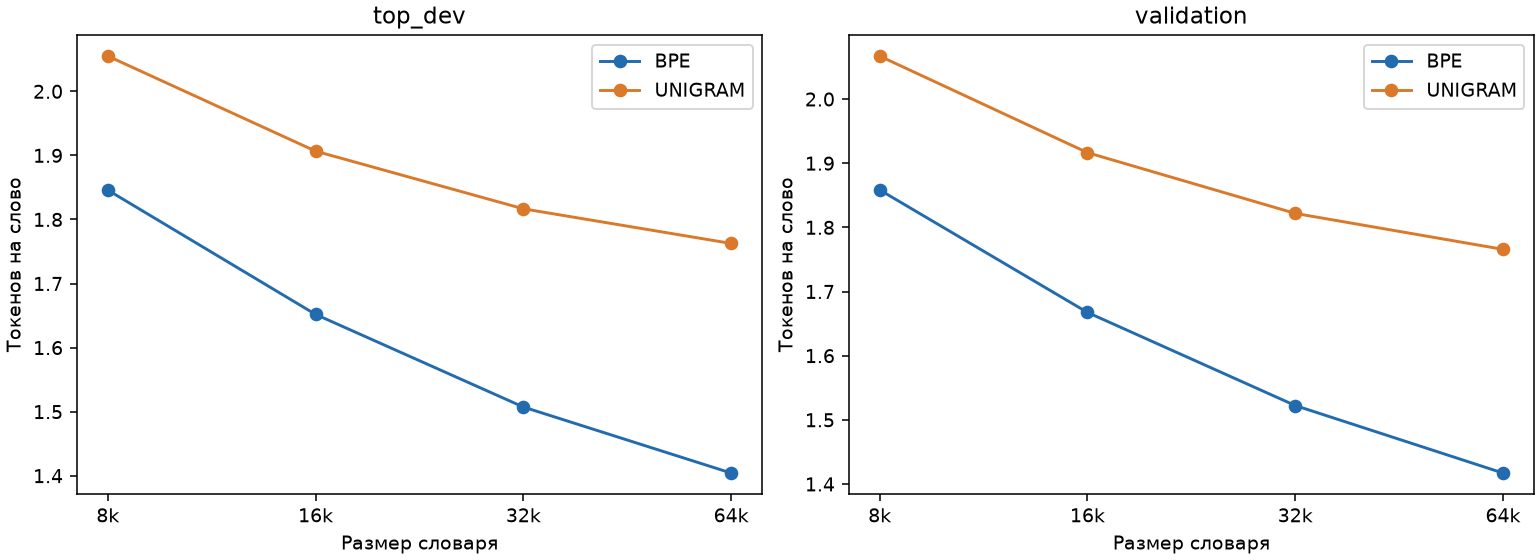

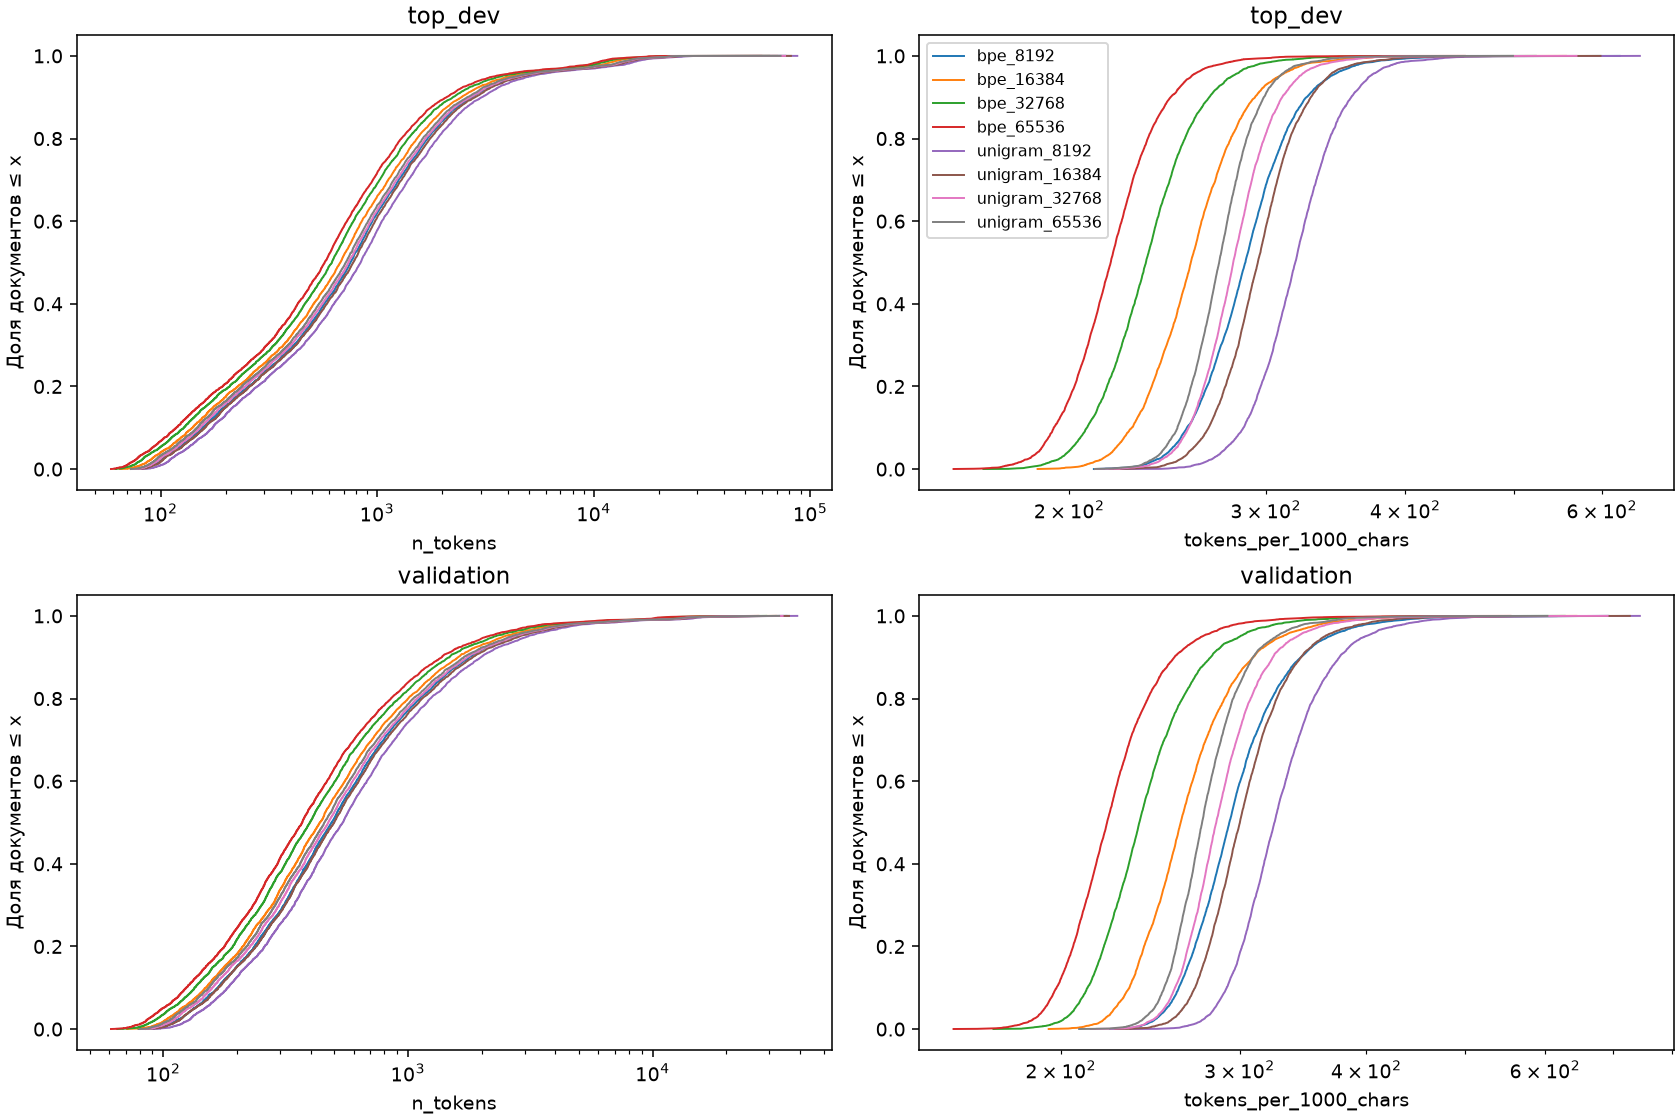

,,over_256,over_512,over_1024
split,candidate,,,
top_dev,bpe_8192,79.9,63.8,37.1
validation,bpe_8192,76.8,47.6,22.1
top_dev,bpe_16384,77.7,59.7,33.2
validation,bpe_16384,72.8,42.9,19.4
top_dev,bpe_32768,75.7,56.7,30.0
validation,bpe_32768,69.3,39.2,17.3
top_dev,bpe_65536,74.1,54.1,27.4
validation,bpe_65536,65.4,35.8,15.5
top_dev,unigram_8192,81.8,66.8,41.2


In [3]:
columns = ["candidate", "tokens", "tokens_per_word", "characters_per_token", "bytes_per_token",
           "length_mean", "length_p50", "length_p90", "length_p95", "length_p99", "length_max",
           "density_p99"]
for split in ["top_dev", "validation"]:
    display(Markdown(f"**{split}**"))
    display(comparison.loc[comparison.split == split, columns].set_index("candidate").round(3))
figure("compression.png")
figure("length_distributions.png")
display(comparison.set_index(["split", "candidate"])[["over_256", "over_512", "over_1024"]].mul(100).round(1))

## Парное сравнение и оценка объёма корпуса

Базовый вариант — BPE-16k. В каждом из 2 000 bootstrap-повторов одни и те же документы получают одинаковые веса у всех токенизаторов. Отрицательная разница означает меньше токенов. Интервалы характеризуют неопределённость выборки, а не вариативность повторного обучения токенизаторов и не качество будущей LLM.

Для оценки полного train используется отношение токенов к символам на Top-dev, умноженное на точно известное число символов миллиона документов. Это оценка, не фактическая токенизация. Один EOS на документ добавит ровно миллион токенов.

In [4]:
delta = paired[["candidate", "split", "token_difference", "difference_low", "difference_high",
                "relative_difference", "relative_low", "relative_high"]].copy()
for col in ["relative_difference", "relative_low", "relative_high"]:
    delta[col] *= 100
display(delta.set_index(["split", "candidate"]).round(2))
volume = estimates.set_index("candidate")[["content_tokens_estimate", "low", "high"]].div(1e9)
volume.columns = ["Токенов контента, млрд", "95% ДИ: низ", "95% ДИ: верх"]
volume["С одним EOS на документ, млрд"] = (estimates.set_index("candidate").content_tokens_estimate + 1_000_000) / 1e9
display(volume.round(4))

token_difference  difference_low  difference_high  \
split      candidate                                                          
top_dev    bpe_8192                 774061       734065.28        815278.08   
           bpe_16384                     0            0.00             0.00   
           bpe_32768               -576759      -607356.60       -546824.62   
           bpe_65536               -987971     -1042670.30       -936403.40   
           unigram_8192            1608932      1521001.78       1699424.22   
           unigram_16384           1016763       959058.00       1076938.95   
           unigram_32768            657649       617287.20        700029.08   
           unigram_65536            441973       410398.70        475321.55   
validation bpe_8192                 476956       451222.78        502022.35   
           bpe_16384                     0            0.00             0.00   
           bpe_32768               -362432      -382156.05       -343478.38   
           bpe_65536               -625353      -657792.85       -592683.85   
           unigram_8192             998094       941893.68       1053801.82   
           unigram_16384            622122       584918.43        659709.78   
           unigram_32768            385567       360358.35        411647.62   
           unigram_65536            245553       225238.02        266309.70   

                          relative_difference  relative_low  relative_high  
split      candidate                                                        
top_dev    bpe_8192                     11.74         11.64          11.84  
           bpe_16384                     0.00          0.00           0.00  
           bpe_32768                    -8.75         -8.82          -8.68  
           bpe_65536                   -14.99        -15.11         -14.87  
           unigram_8192                 24.41         24.26          24.56  
           unigram_16384                15.43         15.23          15.61  
           unigram_32768                 9.98          9.72          10.22  
           unigram_65536                 6.71          6.39           7.01  
validation bpe_8192                     11.45         11.36          11.55  
           bpe_16384                     0.00          0.00           0.00  
           bpe_32768                    -8.70         -8.77          -8.63  
           bpe_65536                   -15.01        -15.13         -14.90  
           unigram_8192                 23.96         23.81          24.12  
           unigram_16384                14.94         14.75          15.13  
           unigram_32768                 9.26          9.01           9.50  
           unigram_65536                 5.90          5.60           6.19

,"Токенов контента, млрд",95% ДИ: низ,95% ДИ: верх,"С одним EOS на документ, млрд"
candidate,,,,
bpe_8192,1.4678,1.4590,1.4774,1.4688
bpe_16384,1.3135,1.3051,1.3225,1.3145
bpe_32768,1.1986,1.1913,1.2065,1.1996
bpe_65536,1.1166,1.1103,1.1234,1.1176
unigram_8192,1.6342,1.6252,1.6440,1.6352
unigram_16384,1.5162,1.5083,1.5249,1.5172
unigram_32768,1.4446,1.4381,1.4517,1.4456
unigram_65536,1.4016,1.3961,1.4077,1.4026


## Использование словаря

Частоты измерены на одинаковых текстах: 50 000 train, 5 000 Top-dev и 5 000 validation. Неиспользуемые и редкие части — наблюдения на этих выборках, а не доказательство их бесполезности во всём языке.

Обученные части, 256 обязательных байтов и четыре служебных токена учитываются отдельно. Служебные токены вручную не добавляются; их нулевые частоты ожидаемы. Некоторые обязательные байты также могут не встречаться. Основная таблица хвоста относится только к **обученным частям**.

Эффективный словарь — exp(H), где H — энтропия эмпирического распределения в натах. Более равномерное распределение само по себе не является целью оптимизации.

У BPE часть с нулевой частотой в итоговом кодировании может участвовать в промежуточных слияниях. Такие части не удаляем автоматически.

,,unused_learned_%,rare_1_9_learned_%,top100_%,top1000_%,entropy_nats,effective_vocabulary
split,candidate,,,,,,
train,bpe_8192,0.00,0.06,37.13,67.97,7.39,1611.66
top_dev,bpe_8192,0.06,0.30,37.26,67.94,7.38,1603.40
validation,bpe_8192,0.13,0.68,37.30,69.14,7.34,1534.60
train,bpe_16384,0.02,0.08,37.15,61.96,7.69,2183.54
top_dev,bpe_16384,0.12,0.87,37.25,61.99,7.68,2161.69
validation,bpe_16384,0.32,3.46,37.32,63.05,7.63,2053.86
train,bpe_32768,0.03,0.20,38.50,58.58,7.91,2724.30
top_dev,bpe_32768,0.34,3.49,38.55,58.68,7.89,2677.48
validation,bpe_32768,1.27,17.01,38.43,59.49,7.84,2539.36


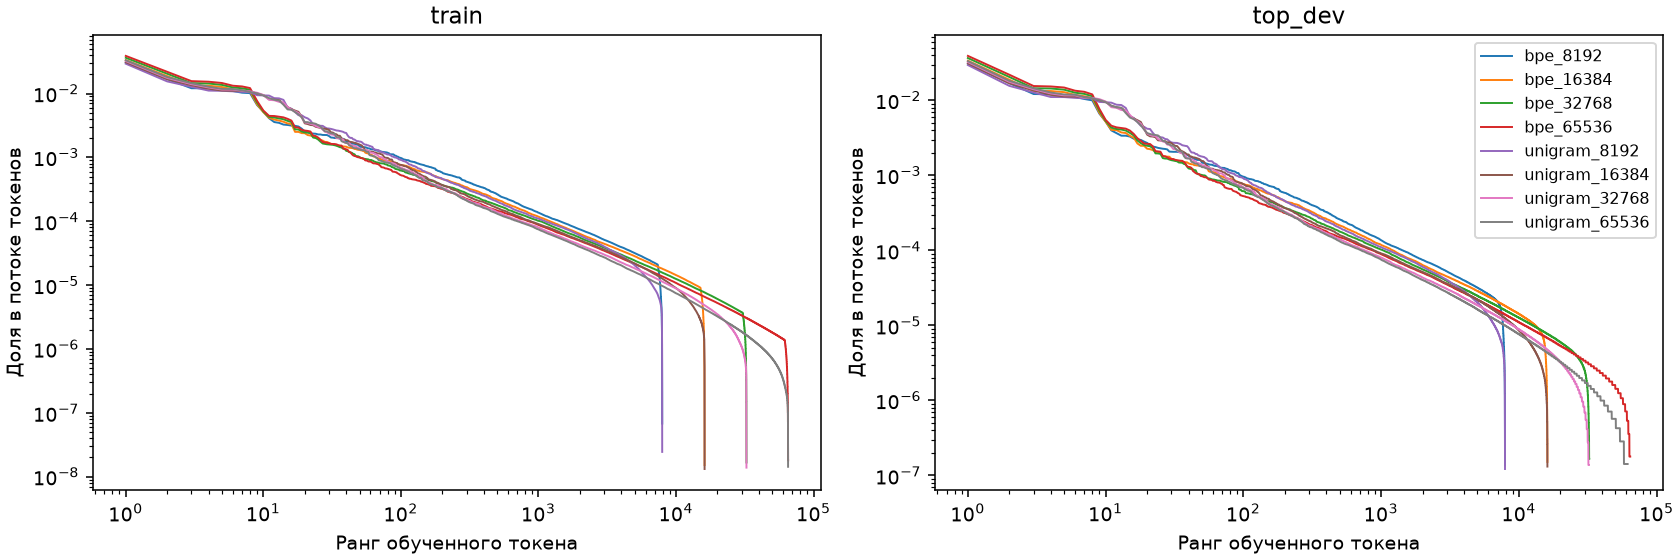

,types,unused,rare_1_9,token_mass
kind,,,,
learned,32508,10,66,0.859546
byte,256,53,1,0.140454
special,4,4,0,0.000000


In [5]:
frequency_rows, kind_rows = [], []
for item in read("frequencies.json"):
    learned = item["by_kind"]["learned"]
    frequency_rows.append({"candidate": item["candidate"], "split": item["split"],
        "unused_learned_%": learned["unused_fraction"]*100,
        "rare_1_9_learned_%": learned["rare_1_9_fraction"]*100,
        "top100_%": item["top100_mass"]*100, "top1000_%": item["top1000_mass"]*100,
        "entropy_nats": item["entropy_nats"], "effective_vocabulary": item["effective_vocabulary"]})
    for kind, values in item["by_kind"].items():
        kind_rows.append({"candidate": item["candidate"], "split": item["split"], "kind": kind, **values})
frequencies = pd.DataFrame(frequency_rows)
display(frequencies.set_index(["split", "candidate"]).round(2))
figure("token_frequencies.png")
kinds = pd.DataFrame(kind_rows)
display(kinds.loc[(kinds.candidate == selection["candidate"]) & (kinds.split == "train")].set_index("kind")[["types", "unused", "rare_1_9", "token_mass"]])

## Скорость и стоимость словаря

Скорость измерена на Top-dev без чтения файлов внутри замера: один полный прогрев, медиана трёх проходов, batch=128, восемь потоков, `encode_batch_fast` без offsets. MB/s — десятичные UTF-8-мегабайты. Tokens/s зависит также от того, сколько токенов создаёт алгоритм; для сравнения скорости обработки текста полезнее MB/s. Фоновая нагрузка машины влияет на результат.

Стоимость общей матрицы embedding/выхода при связанных весах: **V × 1024 параметров**, веса BF16 занимают два байта на параметр. Это не полная память обучения: здесь не учтены градиенты, состояния оптимизатора, активации и logits. Размер 300M и ширина 1024 пока являются предположениями для выбора, а не зафиксированной архитектурой.

,encoding_mb_s,encoding_tokens_s,embedding_parameters,embedding_fraction,embedding_bf16_mib
candidate,,,,,
bpe_8192,42.137,6714100.330,8388608,0.028,16.0
bpe_16384,42.023,5992152.122,16777216,0.056,32.0
bpe_32768,42.441,5522210.306,33554432,0.112,64.0
bpe_65536,41.893,5078153.049,67108864,0.224,128.0
unigram_8192,25.402,4506340.180,8388608,0.028,16.0
unigram_16384,22.713,3738382.492,16777216,0.056,32.0
unigram_32768,21.885,3432012.100,33554432,0.112,64.0
unigram_65536,17.897,2723191.577,67108864,0.224,128.0


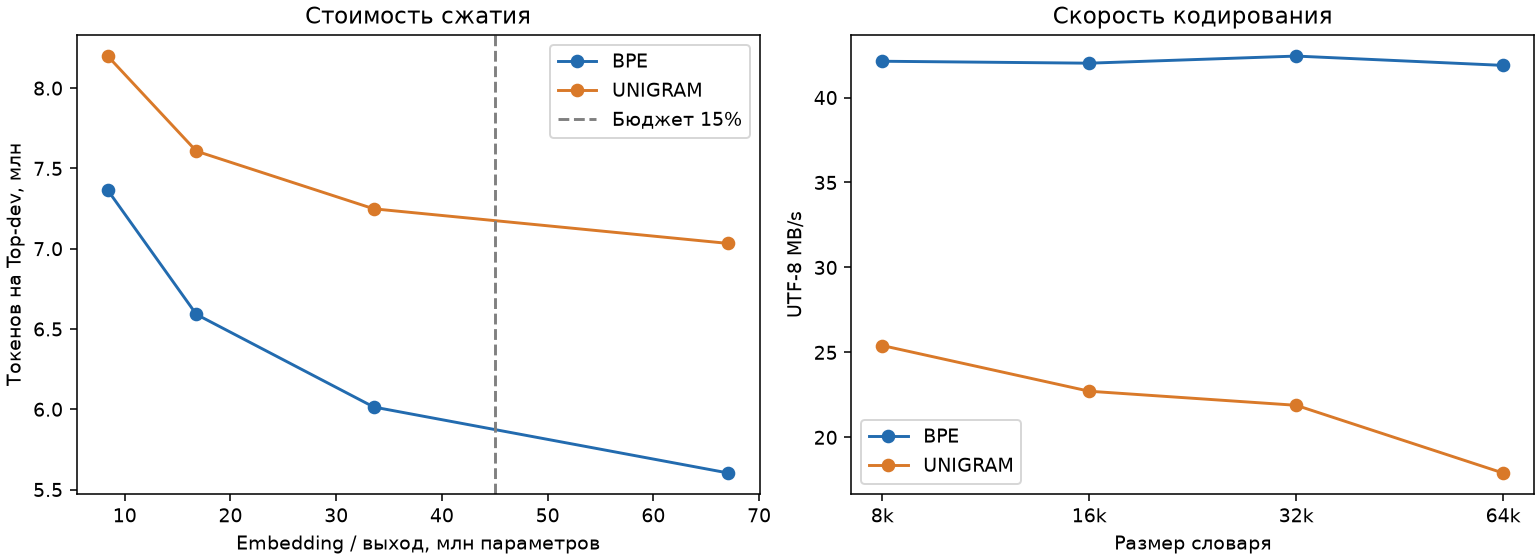

In [6]:
cost = comparison.loc[comparison.split == "top_dev", ["candidate", "encoding_mb_s", "encoding_tokens_s",
                  "embedding_parameters", "embedding_fraction", "embedding_bf16_mib"]].set_index("candidate")
display(cost.round(3))
figure("cost_speed.png")

## Выбор по зафиксированному правилу

Сначала требуем отсутствие UNK и точное восстановление обеих оценочных выборок и контрольных примеров. Общая матрица embedding/выхода должна укладываться в 15% от 300M параметров. При ширине 1024 словарь 64k не проходит бюджет, но показывает возможный дополнительный выигрыш сжатия.

Среди допустимых выбираем наименьший словарь, которому требуется не более 5% дополнительных токенов относительно лучшего допустимого варианта на Top-dev. При одинаковом размере выбираем меньшее число токенов, при точном равенстве — BPE. Validation описывает переносимость; test не участвует. После выбора токенизатор не переобучается.

In [7]:
decision = pd.read_parquet(D / "selection_table.parquet")
display(decision.set_index("candidate")[["tokens", "correct", "within_budget", "within_token_tolerance", "extra_tokens_over_best_eligible"]])
chosen = comparison.loc[(comparison.candidate == selection["candidate"]) & (comparison.split == "top_dev")].iloc[0]
chosen_estimate = estimates.set_index("candidate").loc[selection["candidate"]]
display(Markdown(f"""**Выбран {selection['candidate']}.**

На Top-dev: {chosen.tokens_per_word:.3f} токена на слово, {chosen.characters_per_token:.3f} символа на токен; p99 длины документа — {chosen.length_p99:,.0f} токенов. Матрица embedding/выхода занимает {chosen.embedding_parameters/1e6:.2f} млн параметров ({chosen.embedding_fraction*100:.2f}% от 300M).

Отклонение от лучшего допустимого сжатия — {selection['relative_extra_tokens']*100:.2f}%, при допустимых 5%. Приблизительный объём миллиона документов с одним EOS на документ — {(chosen_estimate.content_tokens_estimate+1_000_000)/1e9:.3f} млрд токенов.

Это выбор по стоимости и свойствам токенизации. Улучшение качества генерации эксперимент не доказывает. При изменении ширины модели или отказе от связанных весов бюджет словаря следует пересчитать."""))
display(pd.Series(verification, name="Проверка сохранения и загрузки").to_frame())

bpe32 = comparison.loc[(comparison.candidate == "bpe_32768") & (comparison.split == "top_dev")].iloc[0]
bpe16 = comparison.loc[(comparison.candidate == "bpe_16384") & (comparison.split == "top_dev")].iloc[0]
bpe64 = comparison.loc[(comparison.candidate == "bpe_65536") & (comparison.split == "top_dev")].iloc[0]
uni32 = comparison.loc[(comparison.candidate == "unigram_32768") & (comparison.split == "top_dev")].iloc[0]
ci32 = paired.loc[(paired.candidate == "bpe_32768") & (paired.split == "top_dev")].iloc[0]
f32 = frequencies.loc[(frequencies.candidate == "bpe_32768") & (frequencies.split == "top_dev")].iloc[0]
display(Markdown(f"""Практические выводы из этого эксперимента:

- BPE-32k использует на {(1-bpe32.tokens/bpe16.tokens)*100:.2f}% меньше токенов, чем BPE-16k; парный 95% интервал сокращения — [{-ci32.relative_high*100:.2f}; {-ci32.relative_low*100:.2f}]%. Обратно, 16k требует на {(bpe16.tokens/bpe32.tokens-1)*100:.2f}% больше токенов и не проходит допуск 5%.
- BPE-64k сокращает число токенов ещё на {(1-bpe64.tokens/bpe32.tokens)*100:.2f}% относительно 32k, но удваивает матрицу до {bpe64.embedding_parameters/1e6:.2f} млн параметров и превышает принятый бюджет.
- При 32k BPE выдаёт на {(1-bpe32.tokens/uni32.tokens)*100:.2f}% меньше токенов, чем Unigram, и в этом замере кодирует текст в {bpe32.encoding_mb_s/uni32.encoding_mb_s:.2f} раза быстрее. Это вывод для нашей общей схемы ByteLevel, не для всех возможных конфигураций Unigram.
- На Top-dev у BPE-32k не встретилось {f32['unused_learned_%']:.2f}% обученных частей; {f32['rare_1_9_learned_%']:.2f}% встретились 1–9 раз. Массового неиспользования словаря на этой выборке не видно.
- q99 длины документа превышает 12 тысяч токенов. На этапе подготовки обучения понадобится упаковка/разбиение длинных документов; механически обрезать каждый до контекста означало бы терять данные.
"""))


,tokens,correct,within_budget,within_token_tolerance,extra_tokens_over_best_eligible
candidate,,,,,
bpe_8192,7364796,True,True,False,0.224613
bpe_16384,6590735,True,True,False,0.095903
bpe_32768,6013976,True,True,True,0.000000
bpe_65536,5602764,True,False,True,-0.068376
unigram_8192,8199667,True,True,False,0.363435
unigram_16384,7607498,True,True,False,0.264970
unigram_32768,7248384,True,True,False,0.205257
unigram_65536,7032708,True,False,False,0.169394


**Выбран bpe_32768.**

На Top-dev: 1.507 токена на слово, 4.303 символа на токен; p99 длины документа — 12,177 токенов. Матрица embedding/выхода занимает 33.55 млн параметров (11.18% от 300M).

Отклонение от лучшего допустимого сжатия — 0.00%, при допустимых 5%. Приблизительный объём миллиона документов с одним EOS на документ — 1.200 млрд токенов.

Это выбор по стоимости и свойствам токенизации. Улучшение качества генерации эксперимент не доказывает. При изменении ширины модели или отказе от связанных весов бюджет словаря следует пересчитать.

,Проверка сохранения и загрузки
candidate,bpe_32768
documents_and_edge_cases,10011
checked_tokens,9816822
same_ids_after_reload,True
exact_roundtrip,True
special_ids,"{'[PAD]': 0, '[UNK]': 1, '[BOS]': 2, '[EOS]': 3}"
literal_special_strings_are_plain_text,True
passed,True


Практические выводы из этого эксперимента:

- BPE-32k использует на 8.75% меньше токенов, чем BPE-16k; парный 95% интервал сокращения — [8.68; 8.82]%. Обратно, 16k требует на 9.59% больше токенов и не проходит допуск 5%.
- BPE-64k сокращает число токенов ещё на 6.84% относительно 32k, но удваивает матрицу до 67.11 млн параметров и превышает принятый бюджет.
- При 32k BPE выдаёт на 17.03% меньше токенов, чем Unigram, и в этом замере кодирует текст в 1.94 раза быстрее. Это вывод для нашей общей схемы ByteLevel, не для всех возможных конфигураций Unigram.
- На Top-dev у BPE-32k не встретилось 0.34% обученных частей; 3.49% встретились 1–9 раз. Массового неиспользования словаря на этой выборке не видно.
- q99 длины документа превышает 12 тысяч токенов. На этапе подготовки обучения понадобится упаковка/разбиение длинных документов; механически обрезать каждый до контекста означало бы терять данные.


## Примеры частей и сегментации

Пробел внутри части показан символом ␠. Если отдельный токен содержит только часть UTF-8-символа, отображаются его байты: это допустимо, а вся последовательность должна декодироваться точно. Такие части нельзя интерпретировать как отдельные повреждённые символы.

Ниже — фиксированные примеры для победителя и редкие/частые обученные части. Полные примеры всех восьми вариантов и частотные таблицы сохранены в артефактах.

In [8]:
example_rows = read(f"candidates/{selection['candidate']}/examples.json")
with pd.option_context("display.max_colwidth", 180):
    display(pd.DataFrame({"Текст": [repr(x["text"]) for x in example_rows],
                          "Части": [" | ".join(x["readable_pieces"]) for x in example_rows],
                          "Токенов": [len(x["ids"]) for x in example_rows],
                          "Точное восстановление": [x["roundtrip"] for x in example_rows]}))
vocab = pd.read_parquet(D / f"candidates/{selection['candidate']}/vocabulary.parquet")
learned = vocab.loc[vocab.kind == "learned"]
display(learned.nlargest(12, "count_train")[["readable", "count_train", "count_top_dev", "count_validation"]])
display(learned.sort_values(["count_train", "token_id"]).head(12)[["readable", "count_train", "count_top_dev", "count_validation"]])

,Текст,Части,Токенов,Точное восстановление
0,'Българският език има богата история. Учениците четат книги в библиотеката.',Бълга | рският | ␠език | ␠има | ␠богата | ␠история | . | ␠Уче | ниците | ␠четат | ␠книги | ␠в | ␠библиотеката | .,14,True
1,'учител учителка учители училище училищата',у | чител | ␠учителка | ␠учители | ␠училище | ␠училищата,6,True
2,"'На 25.10.2026 г. цената е 123,45 лв., а отстъпката — 15%.'","На | ␠25 | . | 10 | . | 20 | 26 | ␠г | . | ␠цената | ␠е | ␠12 | 3 | , | 45 | ␠лв | ., | ␠а | ␠отстъп | ката | ␠— | ␠15 | %.",23,True
3,'Вижте https://example.bg/path?q=София&n=42 или пишете на info@example.bg.',Вижте | ␠https | :// | example | . | bg | / | p | ath | ? | q | = | София | & | n | = | 42 | ␠или | ␠пишете | ␠на | ␠in | f | o | @ | example | . | bg | .,28,True
4,"'София / Sofia: Python и машинно обучение, hello world!'","София | ␠/ | ␠S | of | ia | : | ␠Python | ␠и | ␠маши | нно | ␠обучение | , | ␠h | ello | ␠w | orld | !",17,True
5,' два интервала\tтаб\nнов ред\r\nкрай ',␠ | ␠два | ␠ | ␠интер | вала | \t | та | б | \n | нов | ␠ред | \r | \n | край | ␠ | ␠,16,True
6,'й й; ѝ ѝ; café café; 😀🧑🏽\u200d💻 中文 العربية',й | ␠и | <bytes:cc> | <bytes:86> | ; | ␠ѝ | ␠и | ̀ | ; | ␠c | af | é | ␠c | afe | ́ | ; | ␠ | <bytes:f0 9f> | <bytes:98> | <bytes:80> | <bytes:f0 9f> | <bytes:a7> | <bytes:91> ...,46,True
7,'Литералите [PAD] [UNK] [BOS] [EOS] са обикновен текст.',Лите | ра | лите | ␠[ | PA | D | ] | ␠[ | UN | K | ] | ␠[ | B | OS | ] | ␠[ | E | OS | ] | ␠са | ␠обикновен | ␠текст | .,23,True
8,'',,0,True
9,' \t\n\r\n',␠ | \t | \n | \r | \n,5,True


,readable,count_train,count_top_dev,count_validation
282,␠на,2182133,220499,130542
288,␠и,1223366,123233,80612
321,␠да,875722,87249,61631
290,␠в,862321,86628,52047
319,␠се,820308,83441,48520
314,␠от,748719,76172,45373
312,␠е,726620,73391,42236
309,␠за,691080,68276,53817
273,␠с,433808,43750,31136
307,␠по,314468,32035,21851


,readable,count_train,count_top_dev,count_validation
2781,нъж,0,0,0
4202,ледователно,0,0,0
4317,<bytes:84 96>,0,0,0
5601,увства,0,0,1
7860,␠кръвообра,0,0,0
8074,␠отпе,0,0,0
11290,␠здравеопа,0,0,0
12304,акрая,0,1,0
13598,␠благосъ,0,1,0
15994,␠съни,0,0,1


## Использование выбранного токенизатора

Готовый каталог `artifacts/tokenizers/selected/` загружается через Transformers. Проверены совпадение ID и точное восстановление всех 10 000 отложенных документов и контрольных примеров после сохранения/загрузки. При будущей упаковке документов EOS нужно добавлять явно как ID; буквальная строка `[EOS]` в пользовательском тексте не должна становиться управляющим токеном.

```python
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("artifacts/tokenizers/selected", local_files_only=True)
ids = tokenizer.encode("Българският език има богата история.", add_special_tokens=False)
text = tokenizer.decode(ids, skip_special_tokens=False, clean_up_tokenization_spaces=False)
# При подготовке обучения: document_ids = ids + [tokenizer.eos_token_id]
```

Модели, полные конфигурации тренеров, исходные измерения и контрольные суммы находятся в `artifacts/tokenizers/`. Графики и оценки объёма используют сохранённые результаты; полный train ещё не токенизирован.